# BTXRD 3-Class ROI-Guided ResNet50 + CBAM

**Goal:** a single Kaggle notebook for a reproducible three-class BTXRD experiment:

- **0 = Normal**
- **1 = Benign**
- **2 = Malignant**
- ROI extraction from the original BTXRD LabelMe JSON annotations
- ImageNet-pretrained **ResNet50**
- Lightweight **CBAM** attention module
- Weighted cross-entropy for class imbalance
- Stratified 5-fold cross-validation
- AMP/mixed precision for Kaggle GPU
- Early stopping + best-checkpoint saving
- Accuracy, balanced accuracy, macro precision/recall/F1, macro AUC
- Confusion matrix and OOF predictions
- Grad-CAM-style visual explanation for the trained model

The BTXRD release contains 3,746 radiographs, with 1,879 normal, 1,525 benign and 342 malignant cases. Tumor images have LabelMe JSON annotations containing bounding boxes/polygons; normal images do not require an ROI and are therefore kept as full images.

**Research positioning:** this is intentionally much simpler than the full Ocak et al. pipeline while retaining the important ROI idea and using ResNet50 + lightweight attention as the proposed model.

In [1]:
# ============================================================
# 1. IMPORTS — RUN THIS CELL FIRST
# ============================================================
import os
import gc
import json
import math
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import ResNet50_Weights

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
else:
    print("WARNING: GPU is not enabled. In Kaggle, turn on GPU under Settings > Accelerator.")

SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False

seed_everything(SEED)

PyTorch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
Device: cuda
GPU: Tesla T4
CUDA: 12.8


In [2]:
# ============================================================
# 2. EXPERIMENT CONFIGURATION
# ============================================================
# This is the recommended practical configuration.
# If your Kaggle GPU has enough VRAM, batch_size=32 is usually fine.
# For a 16 GB GPU, reduce to 16.

IMAGE_SIZE = 384
BATCH_SIZE = 24
NUM_WORKERS = min(4, os.cpu_count() or 2)

N_FOLDS = 5
EPOCHS = 18
PATIENCE = 4

LR = 2e-4
WEIGHT_DECAY = 1e-4

# Warm up the classifier head first, then fine-tune the whole network.
WARMUP_EPOCHS = 2
HEAD_LR = 1e-3

ROI_PADDING = 0.10

# Set True to train plain ResNet50 instead of ResNet50+CBAM.
# Keep False for the proposed model.
USE_CBAM = False

# Set True only if you want to save all fold checkpoints.
SAVE_FOLD_CHECKPOINTS = True

CLASS_NAMES = ["Normal", "Benign", "Malignant"]
NUM_CLASSES = 3

OUTPUT_DIR = Path("/kaggle/working/btxrd_resnet50_cbam")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration:")
print("IMAGE_SIZE =", IMAGE_SIZE)
print("BATCH_SIZE =", BATCH_SIZE)
print("N_FOLDS    =", N_FOLDS)
print("EPOCHS     =", EPOCHS)
print("USE_CBAM   =", USE_CBAM)
print("OUTPUT_DIR =", OUTPUT_DIR)

Configuration:
IMAGE_SIZE = 384
BATCH_SIZE = 24
N_FOLDS    = 5
EPOCHS     = 18
USE_CBAM   = False
OUTPUT_DIR = /kaggle/working/btxrd_resnet50_cbam


In [3]:
# ============================================================
# 3. AUTOMATICALLY FIND THE BTXRD DATASET
# ============================================================
# Expected BTXRD structure:
#   dataset.xlsx
#   images/
#       IMGxxxxxx.jpeg
#   Annotations/
#       IMGxxxxxx.json
#
# The code also searches recursively, so it does not depend on
# the exact Kaggle dataset slug.

KAGGLE_INPUT = Path("/kaggle/input")

xlsx_candidates = list(KAGGLE_INPUT.rglob("dataset.xlsx"))
csv_candidates = list(KAGGLE_INPUT.rglob("dataset.csv"))

if not xlsx_candidates and not csv_candidates:
    raise FileNotFoundError(
        "Could not find dataset.xlsx or dataset.csv under /kaggle/input. "
        "Use Kaggle 'Add Input' and add the BTXRD dataset."
    )

print("Spreadsheet candidates:")
for p in xlsx_candidates + csv_candidates:
    print(" -", p)

DATA_TABLE = None
for p in xlsx_candidates:
    try:
        test = pd.read_excel(p, nrows=3)
        cols = {str(c).strip().lower() for c in test.columns}
        if "image_id" in cols and ("benign" in cols or "malignant" in cols):
            DATA_TABLE = p
            break
    except Exception:
        pass

if DATA_TABLE is None:
    for p in csv_candidates:
        try:
            test = pd.read_csv(p, nrows=3)
            cols = {str(c).strip().lower() for c in test.columns}
            if "image_id" in cols and ("benign" in cols or "malignant" in cols):
                DATA_TABLE = p
                break
        except Exception:
            pass

if DATA_TABLE is None:
    raise FileNotFoundError(
        "Found spreadsheet files, but none looked like the BTXRD metadata table."
    )

DATA_ROOT = DATA_TABLE.parent

# Prefer sibling images / Annotations directories.
image_dirs = []
annotation_dirs = []

for base in [DATA_ROOT] + list(DATA_ROOT.parents):
    for name in ["images", "Images"]:
        p = base / name
        if p.exists() and p.is_dir():
            image_dirs.append(p)
    for name in ["Annotations", "annotations"]:
        p = base / name
        if p.exists() and p.is_dir():
            annotation_dirs.append(p)

# Fallback: recursive search.
if not image_dirs:
    image_dirs = [p for p in KAGGLE_INPUT.rglob("images") if p.is_dir() or p.name == "images"]
if not annotation_dirs:
    annotation_dirs = [p for p in KAGGLE_INPUT.rglob("Annotations") if p.is_dir()]

if not image_dirs:
    raise FileNotFoundError("Could not find the BTXRD images directory.")
if not annotation_dirs:
    print("WARNING: Annotations directory not found. Tumor images will use full-image input.")

IMAGE_DIR = image_dirs[0]
ANNOTATION_DIR = annotation_dirs[0] if annotation_dirs else None

print("\nSelected dataset:")
print("DATA_TABLE     :", DATA_TABLE)
print("IMAGE_DIR      :", IMAGE_DIR)
print("ANNOTATION_DIR :", ANNOTATION_DIR)

Spreadsheet candidates:
 - /kaggle/input/datasets/ngcnghatrn/bone-tumor-x-ray-radiograph-dataset-btxrd/BTXRD/dataset.xlsx

Selected dataset:
DATA_TABLE     : /kaggle/input/datasets/ngcnghatrn/bone-tumor-x-ray-radiograph-dataset-btxrd/BTXRD/dataset.xlsx
IMAGE_DIR      : /kaggle/input/datasets/ngcnghatrn/bone-tumor-x-ray-radiograph-dataset-btxrd/BTXRD/images
ANNOTATION_DIR : /kaggle/input/datasets/ngcnghatrn/bone-tumor-x-ray-radiograph-dataset-btxrd/BTXRD/Annotations


In [4]:
# ============================================================
# 4. LOAD METADATA AND CREATE THE EXACT 3 CLASS LABEL
# ============================================================
if DATA_TABLE.suffix.lower() == ".xlsx":
    raw_df = pd.read_excel(DATA_TABLE)
else:
    raw_df = pd.read_csv(DATA_TABLE)

raw_df.columns = [str(c).strip() for c in raw_df.columns]

# Case-insensitive column lookup.
colmap = {c.lower(): c for c in raw_df.columns}

def find_col(name):
    if name.lower() in colmap:
        return colmap[name.lower()]
    return None

IMAGE_ID_COL = find_col("image_id")
BENIGN_COL = find_col("benign")
MALIGNANT_COL = find_col("malignant")
TUMOR_COL = find_col("tumor")

if IMAGE_ID_COL is None:
    raise KeyError("BTXRD metadata must contain image_id.")

print("Metadata columns:")
print(raw_df.columns.tolist())

def as_binary(v):
    if pd.isna(v):
        return 0
    if isinstance(v, str):
        s = v.strip().lower()
        if s in {"1", "true", "yes", "y", "t"}:
            return 1
        return 0
    try:
        return int(float(v) != 0)
    except Exception:
        return 0

df = raw_df.copy()

# Exact BTXRD global 3-class mapping:
# malignant -> 2, benign -> 1, otherwise normal -> 0.
benign_values = df[BENIGN_COL].map(as_binary) if BENIGN_COL else pd.Series(0, index=df.index)
malignant_values = df[MALIGNANT_COL].map(as_binary) if MALIGNANT_COL else pd.Series(0, index=df.index)

if ((benign_values == 1) & (malignant_values == 1)).any():
    raise ValueError("Some rows are simultaneously marked benign and malignant.")

df["label"] = np.where(
    malignant_values.to_numpy() == 1,
    2,
    np.where(benign_values.to_numpy() == 1, 1, 0)
).astype(np.int64)

df["image_id"] = df[IMAGE_ID_COL].astype(str).str.strip()

# Normalize image names.
def normalize_image_id(x):
    x = str(x).strip()
    if not Path(x).suffix:
        x = x + ".jpeg"
    return x

df["image_id"] = df["image_id"].map(normalize_image_id)

print("\nRaw BTXRD class distribution:")
print(df["label"].value_counts().sort_index())

expected = {0: 1879, 1: 1525, 2: 342}
actual = df["label"].value_counts().sort_index().to_dict()
print("\nExpected BTXRD counts:", expected)
print("Observed counts       :", actual)

if actual != expected:
    print("NOTE: Counts differ from the canonical BTXRD release. This can happen if the Kaggle copy was modified.")
    print("The notebook will use the labels actually present in your supplied metadata.")

print("\nClass names:")
for i, name in enumerate(CLASS_NAMES):
    print(i, "-", name)

Metadata columns:
['image_id', 'center', 'age', 'gender', 'hand', 'ulna', 'radius', 'humerus', 'foot', 'tibia', 'fibula', 'femur', 'hip bone', 'ankle-joint', 'knee-joint', 'hip-joint', 'wrist-joint', 'elbow-joint', 'shoulder-joint', 'tumor', 'benign', 'malignant', 'osteochondroma', 'multiple osteochondromas', 'simple bone cyst', 'giant cell tumor', 'osteofibroma', 'synovial osteochondroma', 'other bt', 'osteosarcoma', 'other mt', 'upper limb', 'lower limb', 'pelvis', 'frontal', 'lateral', 'oblique']

Raw BTXRD class distribution:
label
0    1879
1    1525
2     342
Name: count, dtype: int64

Expected BTXRD counts: {0: 1879, 1: 1525, 2: 342}
Observed counts       : {0: 1879, 1: 1525, 2: 342}

Class names:
0 - Normal
1 - Benign
2 - Malignant


In [5]:
# ============================================================
# 5. RESOLVE IMAGE PATHS ROBUSTLY
# ============================================================
image_lookup = {}

for p in IMAGE_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
        image_lookup[p.name.lower()] = p

def resolve_image_path(image_id):
    key = Path(str(image_id)).name.lower()
    if key in image_lookup:
        return str(image_lookup[key])

    # Try stem matching.
    stem = Path(str(image_id)).stem.lower()
    for k, p in image_lookup.items():
        if Path(k).stem.lower() == stem:
            return str(p)

    return None

df["image_path"] = df["image_id"].map(resolve_image_path)

missing_images = df["image_path"].isna().sum()
print("Images found :", len(df) - missing_images)
print("Images missing:", missing_images)

if missing_images:
    print("First missing image IDs:")
    print(df.loc[df["image_path"].isna(), "image_id"].head(20).tolist())

df = df[df["image_path"].notna()].reset_index(drop=True)

print("\nFinal usable image count:", len(df))
print(df["label"].value_counts().sort_index())

Images found : 3746
Images missing: 0

Final usable image count: 3746
label
0    1879
1    1525
2     342
Name: count, dtype: int64


In [6]:
# ============================================================
# 6. LABELME JSON ROI EXTRACTION
# ============================================================
# BTXRD annotations are LabelMe JSON files. We derive a bounding
# rectangle from all polygon/rectangle points in each JSON.
# Normal images have no tumor annotation, so they use the full image.

annotation_lookup = {}
if ANNOTATION_DIR is not None:
    for p in ANNOTATION_DIR.rglob("*.json"):
        annotation_lookup[p.stem.lower()] = p

def annotation_for_image(image_id):
    stem = Path(str(image_id)).stem.lower()
    return annotation_lookup.get(stem)

def bbox_from_labelme(json_path):
    if json_path is None or not Path(json_path).exists():
        return None

    try:
        with open(json_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        all_points = []

        for shape in data.get("shapes", []):
            pts = shape.get("points", [])
            for pt in pts:
                if len(pt) >= 2:
                    all_points.append((float(pt[0]), float(pt[1])))

        if not all_points:
            return None

        xs = [p[0] for p in all_points]
        ys = [p[1] for p in all_points]

        return (min(xs), min(ys), max(xs), max(ys))

    except Exception:
        return None

df["annotation_path"] = df["image_id"].map(annotation_for_image)

bbox_cache = {}
for p in df["annotation_path"].dropna().unique():
    bbox_cache[p] = bbox_from_labelme(p)

def get_bbox(image_id):
    ap = annotation_for_image(image_id)
    return bbox_cache.get(ap) if ap else None

df["bbox"] = df["image_id"].map(get_bbox)

tumor_mask = df["label"].isin([1, 2])
tumor_with_roi = tumor_mask & df["bbox"].notna()

print("Total images:", len(df))
print("Tumor images:", int(tumor_mask.sum()))
print("Tumor images with ROI:", int(tumor_with_roi.sum()))

if tumor_mask.sum() > 0 and tumor_with_roi.sum() / tumor_mask.sum() < 0.95:
    print("WARNING: fewer than 95% of tumor images have readable JSON ROIs.")
    print("The remaining tumor images will use the full image instead.")

print("\nROI availability by class:")
print(pd.crosstab(df["label"], df["bbox"].notna()).rename(columns={False:"no_roi", True:"roi"}))

Total images: 3746
Tumor images: 1867
Tumor images with ROI: 1867

ROI availability by class:
bbox   no_roi   roi
label              
0        1879     0
1           0  1525
2           0   342


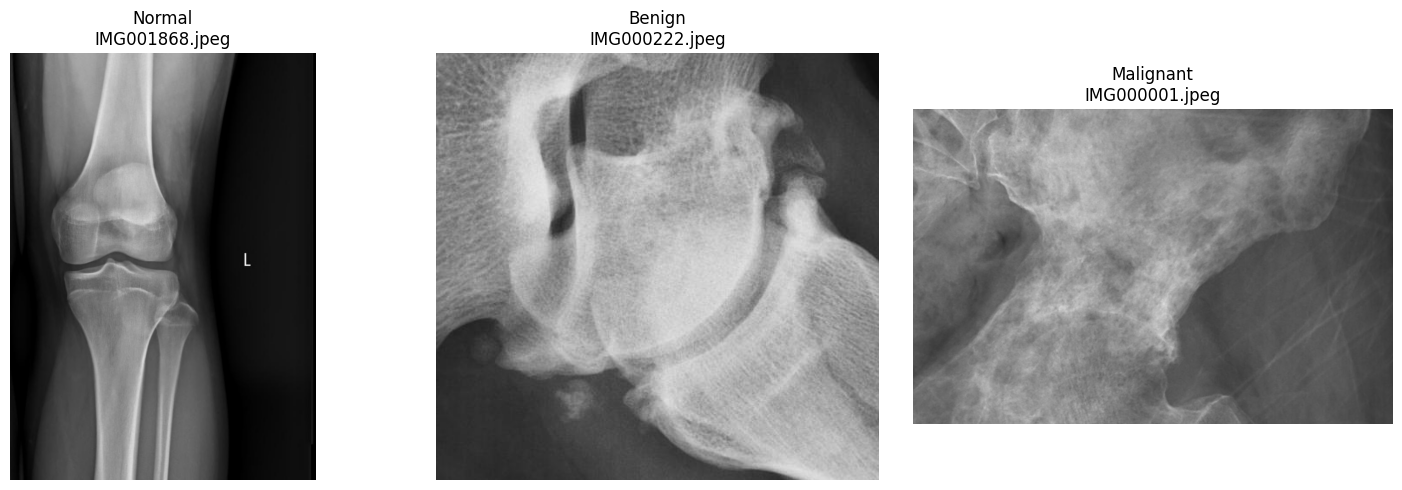

In [7]:
# ============================================================
# 7. VISUAL CHECK OF ROI PIPELINE
# ============================================================
def crop_with_padding(img, bbox, padding=0.10):
    if bbox is None:
        return img

    w, h = img.size
    x1, y1, x2, y2 = bbox

    x1, x2 = sorted([max(0, min(w - 1, x1)), max(0, min(w - 1, x2))])
    y1, y2 = sorted([max(0, min(h - 1, y1)), max(0, min(h - 1, y2))])

    bw = max(1.0, x2 - x1)
    bh = max(1.0, y2 - y1)

    x1 = max(0, int(x1 - bw * padding))
    y1 = max(0, int(y1 - bh * padding))
    x2 = min(w, int(x2 + bw * padding))
    y2 = min(h, int(y2 + bh * padding))

    if x2 <= x1 or y2 <= y1:
        return img

    return img.crop((x1, y1, x2, y2))

samples = []
for cls in [0, 1, 2]:
    sub = df[df["label"] == cls]
    if len(sub):
        samples.append(sub.iloc[0])

fig, axes = plt.subplots(1, len(samples), figsize=(15, 5))
if len(samples) == 1:
    axes = [axes]

for ax, row in zip(axes, samples):
    img = Image.open(row["image_path"]).convert("RGB")
    roi = crop_with_padding(img, row["bbox"], ROI_PADDING)
    ax.imshow(roi)
    ax.set_title(f"{CLASS_NAMES[row['label']]}\n{row['image_id']}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# 8. TRAIN / VALIDATION TRANSFORMS
# ============================================================
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

valid_tfms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class BTXRDDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]

        try:
            img = Image.open(row["image_path"]).convert("RGB")
        except Exception as e:
            raise RuntimeError(f"Could not read image: {row['image_path']} | {e}")

        img = crop_with_padding(img, row["bbox"], ROI_PADDING)

        if self.transform:
            img = self.transform(img)

        y = torch.tensor(int(row["label"]), dtype=torch.long)
        return img, y

print("Dataset class ready.")

Dataset class ready.


In [9]:
# ============================================================
# 9. CBAM MODULE
# ============================================================
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 8)

        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, kernel_size=1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1, bias=False),
        )

    def forward(self, x):
        avg = F.adaptive_avg_pool2d(x, 1)
        mx = F.adaptive_max_pool2d(x, 1)

        attn = torch.sigmoid(self.mlp(avg) + self.mlp(mx))
        return x * attn


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        padding = kernel_size // 2
        self.conv = nn.Conv2d(
            2, 1, kernel_size=kernel_size,
            padding=padding, bias=False
        )

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx, _ = torch.max(x, dim=1, keepdim=True)

        attn = torch.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))
        return x * attn


class CBAM(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.channel = ChannelAttention(channels, reduction)
        self.spatial = SpatialAttention(7)

    def forward(self, x):
        x = self.channel(x)
        x = self.spatial(x)
        return x


class ResNet50CBAM(nn.Module):
    def __init__(self, num_classes=3, use_cbam=True):
        super().__init__()

        weights = ResNet50_Weights.IMAGENET1K_V2
        base = models.resnet50(weights=weights)

        self.conv1 = base.conv1
        self.bn1 = base.bn1
        self.relu = base.relu
        self.maxpool = base.maxpool

        self.layer1 = base.layer1
        self.layer2 = base.layer2
        self.layer3 = base.layer3
        self.layer4 = base.layer4

        self.cbam = CBAM(2048) if use_cbam else nn.Identity()

        self.avgpool = base.avgpool
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.cbam(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


model_test = ResNet50CBAM(NUM_CLASSES, USE_CBAM).to(DEVICE)
print(model_test.__class__.__name__)
print("Parameters:", sum(p.numel() for p in model_test.parameters()) / 1e6, "M")
del model_test
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 195MB/s] 


ResNet50CBAM
Parameters: 23.514179 M


In [10]:
# ============================================================
# 10. LOSS, OPTIMIZER, METRICS, AND AMP HELPERS
# ============================================================
def make_class_weights(train_labels):
    counts = np.bincount(train_labels, minlength=NUM_CLASSES).astype(np.float32)
    weights = counts.sum() / (NUM_CLASSES * np.maximum(counts, 1))
    weights = weights / weights.mean()
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)

def make_optimizer(model, lr=LR):
    return torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=WEIGHT_DECAY
    )

def metrics_from_probs(probs, y_true):
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs)
    preds = probs.argmax(axis=1)

    out = {
        "accuracy": accuracy_score(y_true, preds),
        "balanced_accuracy": balanced_accuracy_score(y_true, preds),
        "precision_macro": precision_score(
            y_true, preds, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            y_true, preds, average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            y_true, preds, average="macro", zero_division=0
        ),
    }

    try:
        out["auc_macro_ovr"] = roc_auc_score(
            y_true, probs, multi_class="ovr", average="macro"
        )
    except Exception:
        out["auc_macro_ovr"] = np.nan

    return out

AMP_ENABLED = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

print("AMP enabled:", AMP_ENABLED)

AMP enabled: True


In [11]:
# ============================================================
# 11. TRAIN / VALIDATE ONE EPOCH
# ============================================================
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    is_train = optimizer is not None
    model.train(is_train)

    running_loss = 0.0
    all_probs = []
    all_y = []

    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=AMP_ENABLED
        ):
            logits = model(x)
            loss = criterion(logits, y)

        if is_train:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

        probs = torch.softmax(logits.detach(), dim=1)

        running_loss += loss.item() * x.size(0)
        all_probs.append(probs.cpu().numpy())
        all_y.append(y.detach().cpu().numpy())

    probs = np.concatenate(all_probs)
    y_true = np.concatenate(all_y)

    metrics = metrics_from_probs(probs, y_true)
    metrics["loss"] = running_loss / len(loader.dataset)

    return metrics, probs, y_true

In [12]:
# ============================================================
# 12. TRAIN ONE FOLD
# ============================================================
def train_one_fold(train_df, val_df, fold):
    print(f"\n{'='*72}")
    print(f"FOLD {fold}/{N_FOLDS}")
    print(f"{'='*72}")

    train_ds = BTXRDDataset(train_df, train_tfms)
    val_ds = BTXRDDataset(val_df, valid_tfms)

    loader_kwargs = dict(
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )

    if NUM_WORKERS > 0:
        loader_kwargs.update(
            persistent_workers=True,
            prefetch_factor=2
        )

    train_loader = DataLoader(
        train_ds, shuffle=True, drop_last=False, **loader_kwargs
    )
    val_loader = DataLoader(
        val_ds, shuffle=False, drop_last=False, **loader_kwargs
    )

    model = ResNet50CBAM(NUM_CLASSES, USE_CBAM).to(DEVICE)

    class_weights = make_class_weights(train_df["label"].to_numpy())
    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=0.05
    )

    # Head warm-up.
    for name, p in model.named_parameters():
        p.requires_grad = name.startswith("fc.")

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=HEAD_LR,
        weight_decay=WEIGHT_DECAY
    )

    best_score = -np.inf
    best_state = None
    bad_epochs = 0

    start_time = time.time()

    # ---------- Stage 1: classifier head warm-up ----------
    for epoch in range(1, WARMUP_EPOCHS + 1):
        tr, _, _ = run_epoch(
            model, train_loader, criterion, optimizer, scaler
        )

        va, _, _ = run_epoch(
            model, val_loader, criterion
        )

        print(
            f"Fold {fold} | Warm {epoch}/{WARMUP_EPOCHS} | "
            f"loss={tr['loss']:.4f} "
            f"train_acc={tr['accuracy']:.4f} "
            f"val_acc={va['accuracy']:.4f} "
            f"val_bal={va['balanced_accuracy']:.4f}"
        )

    # ---------- Stage 2: full fine-tuning ----------
    for p in model.parameters():
        p.requires_grad = True

    optimizer = make_optimizer(model, LR)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS,
        eta_min=LR * 0.05
    )

    for epoch in range(1, EPOCHS + 1):
        tr, _, _ = run_epoch(
            model, train_loader, criterion, optimizer, scaler
        )

        va, va_probs, va_y = run_epoch(
            model, val_loader, criterion
        )

        scheduler.step()

        score = va["balanced_accuracy"]

        if score > best_score:
            best_score = score
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            bad_epochs = 0
        else:
            bad_epochs += 1

        print(
            f"Fold {fold} | Full {epoch}/{EPOCHS} | "
            f"loss={tr['loss']:.4f} "
            f"train_acc={tr['accuracy']:.4f} "
            f"val_acc={va['accuracy']:.4f} "
            f"val_bal={va['balanced_accuracy']:.4f} "
            f"val_f1={va['f1_macro']:.4f}"
        )

        if bad_epochs >= PATIENCE:
            print(f"Fold {fold} | Early stopping.")
            break

    # Restore best validation model.
    model.load_state_dict(best_state)
    model = model.to(DEVICE)

    final_va, probs, y_true = run_epoch(
        model, val_loader, criterion
    )

    elapsed = (time.time() - start_time) / 60.0

    print(
        f"Fold {fold} COMPLETE | "
        f"acc={final_va['accuracy']:.4f} | "
        f"bal_acc={final_va['balanced_accuracy']:.4f} | "
        f"F1={final_va['f1_macro']:.4f} | "
        f"AUC={final_va['auc_macro_ovr']:.4f} | "
        f"time={elapsed:.1f} min"
    )

    if SAVE_FOLD_CHECKPOINTS:
        ckpt_path = OUTPUT_DIR / f"resnet50_{'cbam' if USE_CBAM else 'baseline'}_fold{fold}.pth"
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "image_size": IMAGE_SIZE,
                "roi_padding": ROI_PADDING,
                "use_cbam": USE_CBAM,
                "fold": fold,
                "best_balanced_accuracy": best_score,
            },
            ckpt_path
        )
        print("Saved:", ckpt_path)

    del train_loader, val_loader, train_ds, val_ds, optimizer, scheduler
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return model, probs, y_true, final_va

In [13]:
# ============================================================
# 13. 5-FOLD STRATIFIED CROSS-VALIDATION
# ============================================================
# IMPORTANT:
# Every label is explicitly checked before training.
# This prevents the earlier target-out-of-range errors.

df = df.reset_index(drop=True)
df["label"] = pd.to_numeric(df["label"], errors="raise").astype(np.int64)

unique_labels = sorted(df["label"].unique().tolist())
print("Labels entering CV:", unique_labels)
print("Counts entering CV:")
print(df["label"].value_counts().sort_index())

if unique_labels != [0, 1, 2]:
    raise RuntimeError(
        f"CV aborted: expected labels [0, 1, 2], got {unique_labels}"
    )

if df["label"].value_counts().min() < N_FOLDS:
    raise RuntimeError("The smallest class has fewer samples than N_FOLDS.")

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

fold_results = []
oof_probs = np.zeros((len(df), NUM_CLASSES), dtype=np.float32)
oof_y = df["label"].to_numpy()

total_start = time.time()

for fold, (tr, va) in enumerate(
    skf.split(df, df["label"]),
    start=1
):
    tr_df = df.iloc[tr].reset_index(drop=True)
    va_df = df.iloc[va].reset_index(drop=True)

    # Integrity checks before entering PyTorch.
    tr_labels = sorted(tr_df["label"].unique().tolist())
    va_labels = sorted(va_df["label"].unique().tolist())

    print(
        f"Fold {fold} label check | "
        f"train={tr_labels} | val={va_labels}"
    )

    if tr_labels != [0, 1, 2] or va_labels != [0, 1, 2]:
        raise RuntimeError(
            f"Fold {fold}: invalid labels. "
            f"train={tr_labels}, val={va_labels}"
        )

    model, probs, y, fm = train_one_fold(
        tr_df, va_df, fold
    )

    # y corresponds exactly to va_df order because the validation
    # DataLoader is shuffle=False.
    if len(probs) != len(va):
        raise RuntimeError(
            f"Fold {fold}: probability length {len(probs)} != validation length {len(va)}"
        )

    oof_probs[va] = probs

    row = metrics_from_probs(probs, y)
    row["fold"] = fold
    fold_results.append(row)

results_df = pd.DataFrame(fold_results)

total_minutes = (time.time() - total_start) / 60.0

print("\n" + "="*72)
print("FOLD RESULTS")
print("="*72)
display(results_df)

print("\nMEAN CV METRICS")
display(
    results_df.drop(columns=["fold"]).mean().to_frame("mean").T
)

print(f"\nTotal CV time: {total_minutes:.1f} minutes")

Labels entering CV: [0, 1, 2]
Counts entering CV:
label
0    1879
1    1525
2     342
Name: count, dtype: int64
Fold 1 label check | train=[0, 1, 2] | val=[0, 1, 2]

FOLD 1/5
Fold 1 | Warm 1/2 | loss=0.7159 train_acc=0.8064 val_acc=0.8440 val_bal=0.8090
Fold 1 | Warm 2/2 | loss=0.5928 train_acc=0.8515 val_acc=0.8467 val_bal=0.8257
Fold 1 | Full 1/18 | loss=0.5945 train_acc=0.8852 val_acc=0.9333 val_bal=0.9044 val_f1=0.8750
Fold 1 | Full 2/18 | loss=0.5211 train_acc=0.9062 val_acc=0.9493 val_bal=0.8762 val_f1=0.8848
Fold 1 | Full 3/18 | loss=0.4643 train_acc=0.9346 val_acc=0.9480 val_bal=0.9237 val_f1=0.8997
Fold 1 | Full 4/18 | loss=0.4468 train_acc=0.9496 val_acc=0.9467 val_bal=0.8853 val_f1=0.8828
Fold 1 | Full 5/18 | loss=0.4208 train_acc=0.9583 val_acc=0.9413 val_bal=0.8547 val_f1=0.8634
Fold 1 | Full 6/18 | loss=0.3996 train_acc=0.9606 val_acc=0.9440 val_bal=0.9130 val_f1=0.8877
Fold 1 | Full 7/18 | loss=0.3664 train_acc=0.9756 val_acc=0.9493 val_bal=0.9286 val_f1=0.9016
Fold 1 | 

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,auc_macro_ovr,fold
0,0.973333,0.940762,0.940762,0.940762,0.940762,NaN,1
1,0.962617,0.946971,0.906805,0.946971,0.923681,NaN,2
2,0.962617,0.935324,0.913535,0.935324,0.923512,NaN,3
3,0.954606,0.932369,0.891785,0.932369,0.908518,NaN,4
4,0.974633,0.929717,0.957449,0.929717,0.942418,NaN,5



MEAN CV METRICS


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,auc_macro_ovr
mean,0.965561,0.937028,0.922067,0.937028,0.927778,NaN



Total CV time: 84.6 minutes


FINAL OUT-OF-FOLD METRICS
accuracy            : 0.9656
balanced_accuracy   : 0.9371
precision_macro     : 0.9188
recall_macro        : 0.9371
f1_macro            : 0.9273
auc_macro_ovr       : nan

Classification report:
              precision    recall  f1-score   support

      Normal     0.9979    0.9995    0.9987      1879
      Benign     0.9691    0.9462    0.9575      1525
   Malignant     0.7893    0.8655    0.8257       342

    accuracy                         0.9656      3746
   macro avg     0.9188    0.9371    0.9273      3746
weighted avg     0.9671    0.9656    0.9661      3746

Confusion matrix:
[[1878    0    1]
 [   4 1443   78]
 [   0   46  296]]


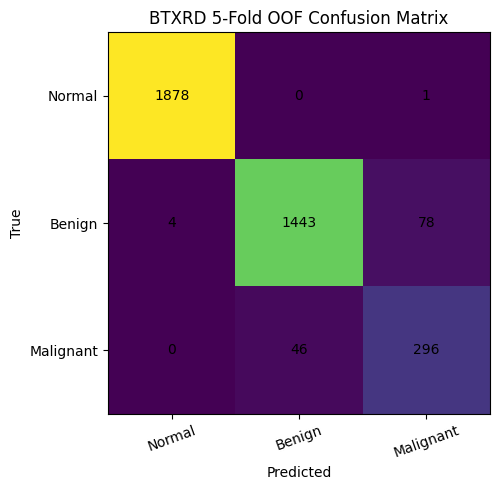


Saved:
/kaggle/working/btxrd_resnet50_cbam/oof_predictions.csv
/kaggle/working/btxrd_resnet50_cbam/fold_results.csv


In [14]:
# ============================================================
# 14. OUT-OF-FOLD FINAL RESULTS
# ============================================================
oof_metrics = metrics_from_probs(oof_probs, oof_y)

print("="*72)
print("FINAL OUT-OF-FOLD METRICS")
print("="*72)

for k, v in oof_metrics.items():
    print(f"{k:20s}: {v:.4f}")

oof_pred = oof_probs.argmax(axis=1)

print("\nClassification report:")
print(
    classification_report(
        oof_y,
        oof_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(oof_y, oof_pred)

print("Confusion matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("BTXRD 5-Fold OOF Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=20)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, int(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()

# Save OOF predictions.
oof_df = df[["image_id", "label"]].copy()
oof_df["predicted"] = oof_pred
for i, name in enumerate(CLASS_NAMES):
    oof_df[f"prob_{name.lower()}"] = oof_probs[:, i]

oof_path = OUTPUT_DIR / "oof_predictions.csv"
oof_df.to_csv(oof_path, index=False)

results_path = OUTPUT_DIR / "fold_results.csv"
results_df.to_csv(results_path, index=False)

print("\nSaved:")
print(oof_path)
print(results_path)

In [15]:
# ============================================================
# 15. SAVE THE FINAL RESEARCH CONFIGURATION
# ============================================================
config = {
    "dataset": "BTXRD",
    "classes": CLASS_NAMES,
    "num_images": int(len(df)),
    "image_size": IMAGE_SIZE,
    "roi_padding": ROI_PADDING,
    "model": "ResNet50 + CBAM" if USE_CBAM else "ResNet50",
    "pretrained": True,
    "loss": "weighted CrossEntropyLoss with label_smoothing=0.05",
    "optimizer": "AdamW",
    "learning_rate": LR,
    "head_learning_rate": HEAD_LR,
    "weight_decay": WEIGHT_DECAY,
    "warmup_epochs": WARMUP_EPOCHS,
    "fine_tune_epochs_max": EPOCHS,
    "early_stopping_patience": PATIENCE,
    "folds": N_FOLDS,
    "seed": SEED,
}

with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

print(json.dumps(config, indent=2))

{
  "dataset": "BTXRD",
  "classes": [
    "Normal",
    "Benign",
    "Malignant"
  ],
  "num_images": 3746,
  "image_size": 384,
  "roi_padding": 0.1,
  "model": "ResNet50",
  "pretrained": true,
  "loss": "weighted CrossEntropyLoss with label_smoothing=0.05",
  "optimizer": "AdamW",
  "learning_rate": 0.0002,
  "head_learning_rate": 0.001,
  "weight_decay": 0.0001,
  "warmup_epochs": 2,
  "fine_tune_epochs_max": 18,
  "early_stopping_patience": 4,
  "folds": 5,
  "seed": 42
}


## Optional: baseline comparison

For the research comparison, rerun the notebook once with:

```python
USE_CBAM = False
```

This gives:

**Experiment A:** ROI-guided ResNet50

Then rerun with:

```python
USE_CBAM = True
```

This gives:

**Experiment B:** ROI-guided ResNet50 + CBAM

The comparison should report the **same folds, seed, preprocessing, optimizer schedule and evaluation metrics**. Do not compare one model using a different split.

A good research claim is not "we guarantee >96.05%." Instead:

> *We evaluate whether lightweight CBAM attention improves ROI-guided ResNet50 performance for three-class BTXRD classification under stratified five-fold cross-validation, and compare the resulting performance with recent BTXRD studies.*

If CBAM improves accuracy/F1/balanced accuracy, that is your proposed-model result. If accuracy does not improve but calibration, minority-class recall or Grad-CAM quality improves, those can also be reported as secondary findings.

## Reference papers

**BTXRD dataset paper:** Yao et al., *A Radiograph Dataset for the Classification, Localization, and Segmentation of Primary Bone Tumors*, Scientific Data (2025).

**Primary three-class reference:** Ocak et al., *A Calibrated Deep Learning Framework Integrating Spatial Annotations and Clinical Metadata for Safe Three-Class Bone Lesion Classification on Radiographs* (2026).

This notebook intentionally does **not** claim to be an exact reproduction of Ocak et al.; it is a simpler ROI-guided ResNet50+CBAM experiment designed for a reproducible research comparison.